<a href="https://colab.research.google.com/github/A-ghori/sklearn/blob/recovery/Gradient_Descent_Scratch2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [45]:
import numpy as np
from sklearn.datasets import make_regression

X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1, random_state=42)

print(X.shape)
print(y.shape)

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X,y)

print(lr.coef_)
print(lr.intercept_)

(4, 1)
(4,)
[15.60186404]
-1.7763568394002505e-15


In [46]:
class GDRegression:
  def __init__(self,m, b, lr, epochs):
    self.m = m
    self.b = b

    self.lr = lr
    self.epochs = epochs

  def fit(self, X, y):

    self.bias_history = []
    self.loss_history = []

    # calculate the b using GD
    for epoch in range(self.epochs):
      loss_slope = -2 * np.sum(y - self.m * X.ravel() - self.b)

      # update the b
      self.b = self.b - loss_slope * self.lr

      # calculate predictions with updates b
      y_pred = self.m * X.ravel() + self.b

      # calculate loss
      loss = np.sum((y - y_pred) ** 2)

      self.bias_history.append(self.b)
      self.loss_history.append(loss)

      print(f"Epoch: {epoch} Loss: {loss}")
      print("Bias is ",self.b)

    return self.b






In [47]:
gd = GDRegression(
    m=15.60186404,
    b=--1.7763568394002505e-15,
    lr=0.01,
    epochs=100
)

print(gd.fit(X, y))

Epoch: 0 Loss: 4.96915628436029e-17
Bias is  2.1465976551837685e-10
Epoch: 1 Loss: 4.594748472577908e-17
Bias is  4.121451155469913e-10
Epoch: 2 Loss: 4.277853777371535e-17
Bias is  5.938316375733166e-10
Epoch: 3 Loss: 4.009633027999757e-17
Bias is  7.609832378375359e-10
Epoch: 4 Loss: 3.782610872975169e-17
Bias is  9.147627100806176e-10
Epoch: 5 Loss: 3.590460823067769e-17
Bias is  1.0562398245442529e-09
Epoch: 6 Loss: 3.4278219011748744e-17
Bias is  1.1863987698507972e-09
Epoch: 7 Loss: 3.290167953226849e-17
Bias is  1.306144999532818e-09
Epoch: 8 Loss: 3.1736561037755225e-17
Bias is  1.4163115308402772e-09
Epoch: 9 Loss: 3.075038498016635e-17
Bias is  1.5176647396431397e-09
Epoch: 10 Loss: 2.99157031341985e-17
Bias is  1.6109096917417732e-09
Epoch: 11 Loss: 2.92092459132318e-17
Bias is  1.6966950476725158e-09
Epoch: 12 Loss: 2.861127125904178e-17
Bias is  1.7756175751287992e-09
Epoch: 13 Loss: 2.810517626818054e-17
Bias is  1.8482263003885799e-09
Epoch: 14 Loss: 2.7676785357262162e-

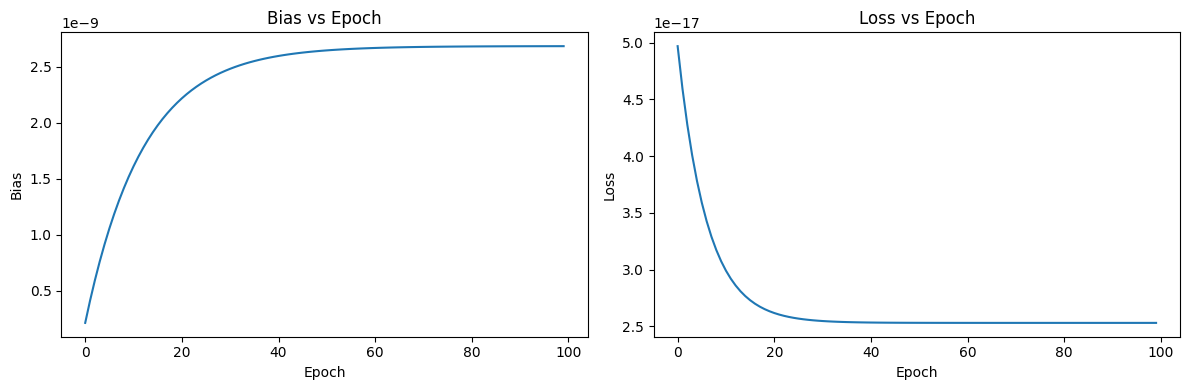

In [48]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Bias graph
ax[0].plot(gd.bias_history)
ax[0].set_title("Bias vs Epoch")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Bias")

# Loss graph
ax[1].plot(gd.loss_history)
ax[1].set_title("Loss vs Epoch")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()